# perf5: Jerome update — simulations and 1KGP

Analyse the completed **perf5** archive: Out-of-Africa simulations with
**50, 500, 5,000 and 50,000 diploid samples** (up to **100,000 haplotypes**)
and 1% genotype error, plus **1KGP chr20p (3,202 diploid samples)**.
In that order, the saved AF cutoffs are **0.1, 0.1, 0.05, 0.05 and 0.1**,
and the minimum focal lengths are **25, 50, 100, 100 and 150 kb**. These are
mean-density equivalents of site-count filters, not strict local physical minima.

There is **one trial per dataset and method**, with **96 matching workers**.
Both methods use the archived recombination settings and mismatch
probability of **10⁻²⁰**. Residual greedy HMM gaps are **unconditioned**;
supported one-site gaps keep their direct-copy rule. The greedy reference
representation preserves back mutations, and all archived called-allele
quality checks must pass before any plots are made.

Lines connect all datasets using one colour and point type per method:
**Full HMM** and **Greedy HMM**. Dataset-panel titles give their saved AF/AC
settings. Cohorts differ in origin, sample size, site density and focal
filtering, so these lines are visual guides, not a controlled scaling
experiment. Lines and points have no benchmark replicate uncertainty.

Inputs are extracted from `data/ch5/perf5_diagnostics.tar.gz`
into `data/ch5/perf5_diagnostics/`. Tables, dated trees and PNG/PDF figures
are cached under its `for_plots/` directory. No genotype stores are opened.
**1KGP has no simulated truth**: it appears in all applicable diagnostics
and in age comparisons against Full HMM, but not in comparisons against truth.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display
import numpy as np
import pandas as pd

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)

/Users/duncan/work/dphil-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
repository_dir = pathlib.Path.cwd()
config_path = {
    "cache_subdir": "for_plots",
    "workers": None,
    "helper_threads": 1,
    "dating": {
        "post_process": {"split_ultimate": True, "erase_flanks": True},
        "preprocess": {"delete_intervals": [], "split_disjoint": True},
        "estimation": {
            "method": "variational_gamma",
            "time_units": "generations",
            "set_metadata": True,
            "progress": False,
            "singletons_phased": True,
        },
    },
    "frequency_bins": {
        "cutoffs": [0.01, 0.5],
        "labels": ["DAF < 0.01", "0.01 ≤ DAF < 0.5", "DAF ≥ 0.5"],
    },
    "title": "perf5",
    "description": "Out-of-Africa simulations and 1KGP · chr20p",
    "data_dir": repository_dir / "data/ch5/perf5_diagnostics",
    "mutation_rate": 2.35e-08,
    "population_groups": {
        "African": ["YRI", "AFR"],
        "Non-African": ["CEU", "CHB", "EUR", "EAS", "SAS", "AMR"],
    },
    "stages": {
        "gap_parent": "gap_matching_assembly",
        "gap_children": [
            "gap_native_find_path",
            "gap_path_conversion",
            "gap_mutation_extraction",
            "gap_final_concatenation",
        ],
    },
}
config_path["base_dir"] = repository_dir
config = nb_utils.paramsearch_load_config(config_path)
plot_data = nb_utils.prepare_scaling_data(config)
logging.basicConfig(level=logging.INFO, format="%(message)s")

## Archived run checks

Sample counts come from saved cohort identities. Saved quality checks verify
called alleles and sample/reference metadata; they do not establish genealogy
accuracy. The resolved site-count minimum is included below. Diagnostic
coverage uses the observed inference-site extent, excluding chromosome flanks.

In [3]:
if __name__ == "__main__":
    cohorts = nb_utils.cohort_table(config)
    performance = nb_utils.performance_runs(config)
    summary = nb_utils.diagnostic_summary(config)
    ipython_display.display(cohorts)
    columns = [
        "num_samples",
        "method",
        "af_cutoff",
        "wall_s",
        "wall_ms_per_haplotype",
        "speedup",
        "effective_cores",
        "trial_peak_private_gib",
    ]
    ipython_display.display(performance[columns].round(3))

,dataset,num_samples,num_haplotypes,num_sites,analysis_span_mb,has_truth,min_region_size_kb,min_focal_region_size
0,out_of_africa_n50_28_1mbp_error,50,100,94665,28.017828,True,25,84
1,out_of_africa_n500_28_1mbp_error,500,1000,207968,28.018744,True,50,371
2,tgp_chr20p_n3202,3202,6404,580909,26.047226,False,150,3345
3,out_of_africa_n5000_28_1mbp_error,5000,10000,490670,28.018831,True,100,1751
4,out_of_africa_n50000_28_1mbp_error,50000,100000,1086350,28.018736,True,100,3877


,num_samples,method,af_cutoff,wall_s,wall_ms_per_haplotype,speedup,effective_cores,trial_peak_private_gib
0,50,full_hmm,NaN,5.921,59.210,1.000,2.266,1.206
1,50,greedy,0.10,25.284,252.837,0.234,7.243,12.131
2,500,full_hmm,NaN,22.683,22.683,1.000,27.981,4.725
3,500,greedy,0.10,51.985,51.985,0.436,8.902,15.058
9,3202,full_hmm,NaN,194.596,30.387,1.000,79.242,16.629
8,3202,greedy,0.10,114.764,17.921,1.696,39.077,22.245
5,5000,full_hmm,NaN,599.040,59.904,1.000,83.615,21.301
4,5000,greedy,0.05,284.207,28.421,2.108,58.163,22.790
6,50000,full_hmm,NaN,29021.918,290.219,1.000,89.402,111.080
7,50000,greedy,0.05,9243.316,92.433,3.140,104.625,66.193


## Performance against sample size

Wall time is the measured end-to-end window. Throughput divides that wall
time by the number of matched haplotypes at fixed worker count. Private memory
is sampled **sum of process-tree USS**, not RSS; shared mappings are not
multiplied by the number of workers. Whole-trial memory also covers work
outside the wall timer, including validation; timed-window memory covers the
same window as wall time. Average cores = (user + system CPU seconds) / wall seconds.
Speedup = Full HMM wall time / method wall time within the same cohort.
The dotted parallelism line marks the 96 matching workers. This is achieved
CPU concurrency, not speedup relative to a single-worker run. Setup and I/O
inside the measured window are included, as in the chapter 3 CPU/wall metric.
The sample-size axis is logarithmic; every measured size is labelled.

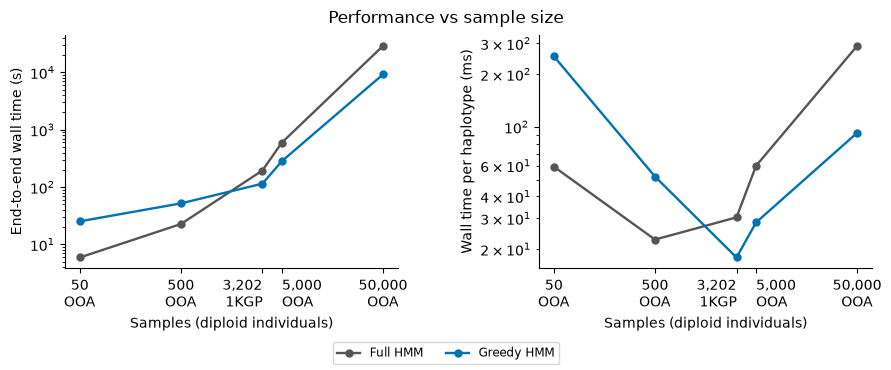

In [4]:
if __name__ == "__main__":
    metrics = {
        "wall_s": "End-to-end wall time (s)",
        "wall_ms_per_haplotype": "Wall time per haplotype (ms)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Performance vs sample size",
            include_full=True,
            log_y=True,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_wall_throughput",
        export_dpi=180,
    )

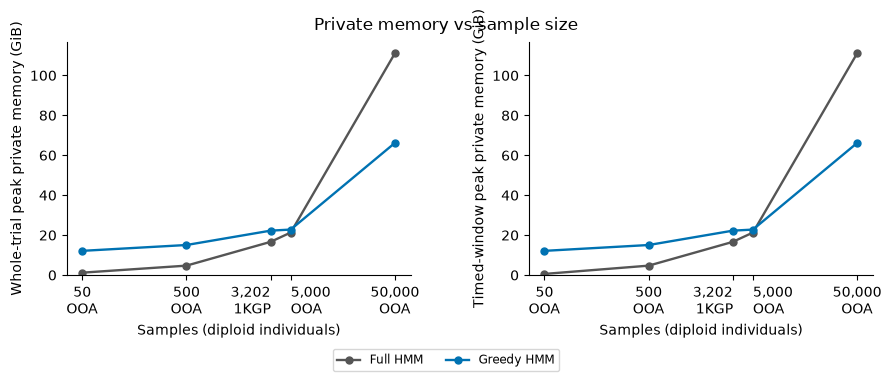

In [5]:
if __name__ == "__main__":
    metrics = {
        "trial_peak_private_gib": "Whole-trial peak private memory (GiB)",
        "window_peak_private_gib": "Timed-window peak private memory (GiB)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Private memory vs sample size",
            include_full=True,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "performance_memory",
        export_dpi=180,
    )

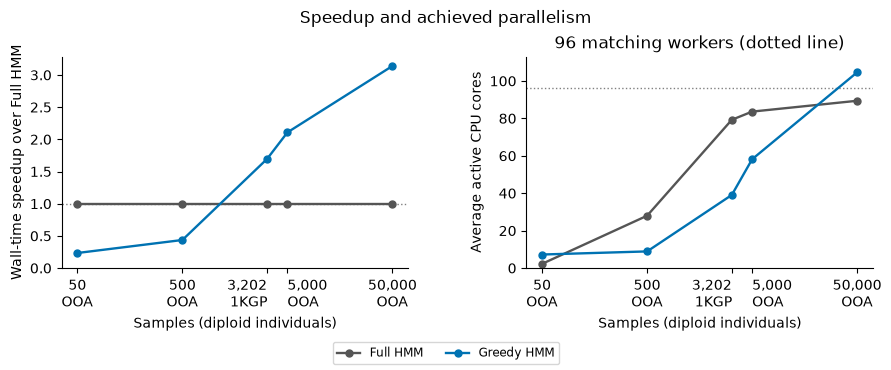

In [6]:
if __name__ == "__main__":
    metrics = {
        "speedup": "Wall-time speedup over Full HMM",
        "effective_cores": "Average active CPU cores",
    }
    figure = nb_plot.plot_scaling(
        plot_data,
        performance,
        metrics,
        "Speedup and achieved parallelism",
        include_full=True,
        cohort_labels={
            "out_of_africa_n50_28_1mbp_error": "50\nOOA",
            "out_of_africa_n500_28_1mbp_error": "500\nOOA",
            "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
            "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
            "tgp_chr20p_n3202": "3,202\n1KGP",
        },
        cutoff_colors=["#0072B2", "#D55E00"],
        full_color="#555555",
        line_width=1.7,
        marker="o",
        marker_size=5,
        method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
        method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
        panel_height=3.6,
        panel_width=4.4,
        range_margin=0.08,
        real_data_marker="o",
        sample_tick_alignments={
            "tgp_chr20p_n3202": "right",
            "out_of_africa_n5000_28_1mbp_error": "left",
        },
        sample_tick_rotation=0,
    )
    workers = config["experiment"]["performance"]["worker_counts"][0]
    nb_plot.plot_performance_against_sample_size_2(
        figure=figure,
        performance=performance,
        workers=workers,
        color="gray",
        linestyle=":",
        linewidth=1,
    )
    nb_plot.save_cohort_figure(
        plot_data, figure, "performance_speedup_parallelism", export_dpi=180
    )

## Where greedy matching spends its time

The first stack partitions end-to-end wall time into sequential coordinator
and process phases. Matching/drain includes sample loading, result waiting
and assembly: its nested timers are not stacked again. Worker packing and
setup can overlap with coordinator phases; only the coordinator's elapsed
windows appear in this plot. The residual makes each stack equal the measured
trial total. In particular, startup and shutdown dominate the smallest run.

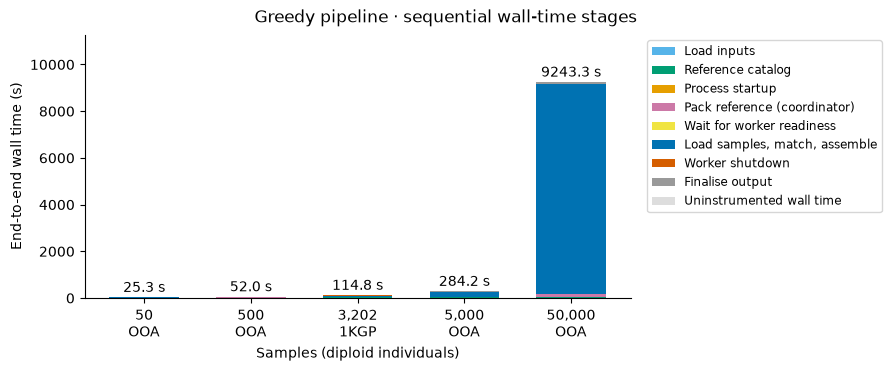

,num_samples,stage,wall_s,service_s
8,50,first_sample_slab_latency,1.656,NaN
9,50,sample_loading_remapping,NaN,1.655
10,50,first_result_latency,1.687,NaN
18,50,coordinator_matching_drain,1.730,NaN
29,500,first_sample_slab_latency,9.330,NaN
30,500,sample_loading_remapping,NaN,9.329
31,500,first_result_latency,9.504,NaN
39,500,coordinator_matching_drain,11.592,NaN
50,5000,first_sample_slab_latency,48.391,NaN
51,5000,sample_loading_remapping,NaN,48.390


In [7]:
if __name__ == "__main__":
    stages = nb_utils.stage_breakdown(config, performance)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_wall_stages(
            plot_data,
            stages,
            bar_width=0.65,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            wall_stages={
                "input_setup": {"label": "Load inputs", "color": "#56B4E9"},
                "reference_catalog": {"label": "Reference catalog", "color": "#009E73"},
                "coordinator_process_startup": {
                    "label": "Process startup",
                    "color": "#E69F00",
                },
                "coordinator_packing_completion": {
                    "label": "Pack reference (coordinator)",
                    "color": "#CC79A7",
                },
                "coordinator_worker_readiness": {
                    "label": "Wait for worker readiness",
                    "color": "#F0E442",
                },
                "coordinator_matching_drain": {
                    "label": "Load samples, match, assemble",
                    "color": "#0072B2",
                },
                "coordinator_shutdown": {
                    "label": "Worker shutdown",
                    "color": "#D55E00",
                },
                "finalise_output": {"label": "Finalise output", "color": "#999999"},
                "other": {"label": "Uninstrumented wall time", "color": "#DDDDDD"},
            },
        ),
        "greedy_wall_stages",
        export_dpi=180,
    )
    latency_stages = [
        "sample_loading_remapping",
        "first_sample_slab_latency",
        "first_result_latency",
        "coordinator_matching_drain",
    ]
    latency = stages.recorded.loc[stages.recorded.stage.isin(latency_stages)]
    ipython_display.display(
        latency[["num_samples", "stage", "wall_s", "service_s"]].round(3)
    )

The next plot separates worker elapsed time from worker thread CPU time,
dividing each summed stage by the number of matched haplotypes. Gap HMM
`find_path`, path conversion, mutation extraction and concatenation replace
the inclusive gap timer; their remainder is shown as other gap work. These
worker totals overlap in wall time and are **not wall-time decompositions**.
Reference packing and worker setup are amortised over matched haplotypes.
Loader timings are shown separately in the table above.

The per-haplotype values below are workload averages. Unlike pt11, this
archive also saves individual greedy task timings in `haplotype_timings.csv`;
they remain available for later analysis. This notebook recreates pt11's
aggregate plots without adding a new per-haplotype timing analysis.

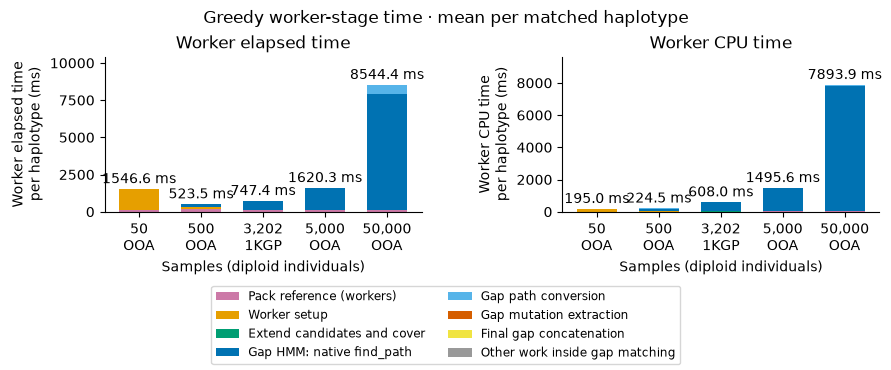

In [8]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_worker_stages(
            plot_data,
            stages,
            bar_width=0.65,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            worker_stages={
                "reference_packing": {
                    "label": "Pack reference (workers)",
                    "color": "#CC79A7",
                },
                "worker_setup": {"label": "Worker setup", "color": "#E69F00"},
                "candidate_extension_cover": {
                    "label": "Extend candidates and cover",
                    "color": "#009E73",
                },
                "gap_native_find_path": {
                    "label": "Gap HMM: native find_path",
                    "color": "#0072B2",
                },
                "gap_path_conversion": {
                    "label": "Gap path conversion",
                    "color": "#56B4E9",
                },
                "gap_mutation_extraction": {
                    "label": "Gap mutation extraction",
                    "color": "#D55E00",
                },
                "gap_final_concatenation": {
                    "label": "Final gap concatenation",
                    "color": "#F0E442",
                },
                "gap_other": {
                    "label": "Other work inside gap matching",
                    "color": "#999999",
                },
            },
        ),
        "greedy_worker_stages",
        export_dpi=180,
    )

## Recorded workload

Focal site coverage uses the timed runner's summed focal/domain site counts,
rather than physical spans. Gap calls count separate HMM invocations. These
are workload measures, not timing decompositions.

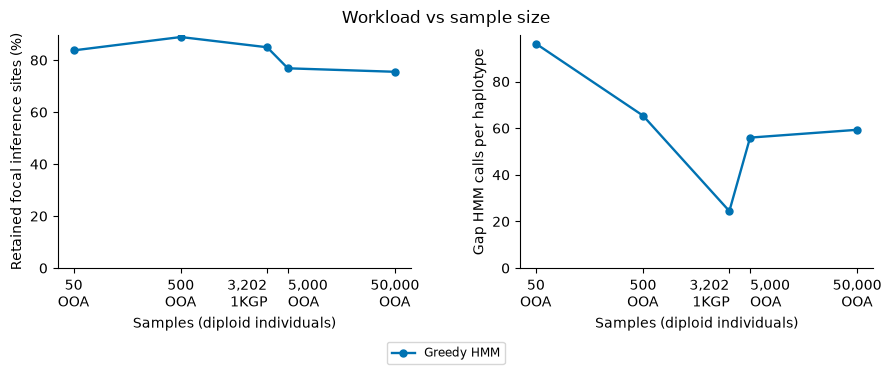

In [9]:
if __name__ == "__main__":
    metrics = {
        "focal_site_coverage_percentage": "Retained focal inference sites (%)",
        "gap_calls_per_haplotype": "Gap HMM calls per haplotype",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            performance,
            metrics,
            "Workload vs sample size",
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "workload_scaling",
        export_dpi=180,
    )

## Extra switches and parent agreement

Each diagnostic mean weights haplotypes equally. Error bars are one
haplotype SEM within a cohort; paired haplotypes are dependent and these are
not simulation or benchmark replicate errors. Percentage switch increases
are calculated per haplotype before averaging. Parent agreement denominators
are evaluated inference sites in focal regions or gaps. Its y axes cover the
displayed means and SEMs rather than starting at zero.

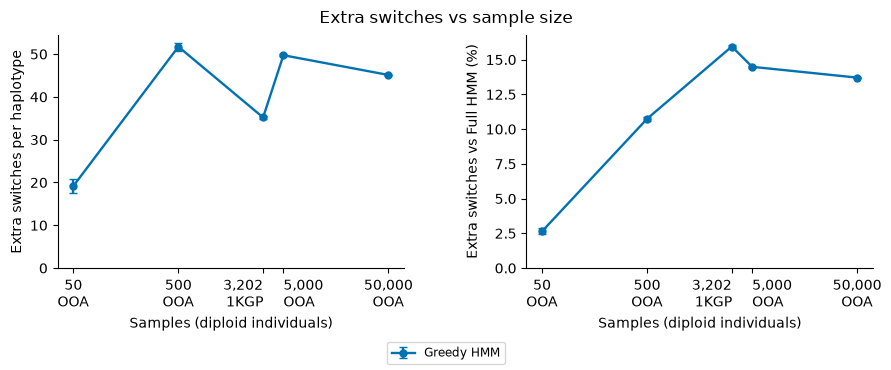

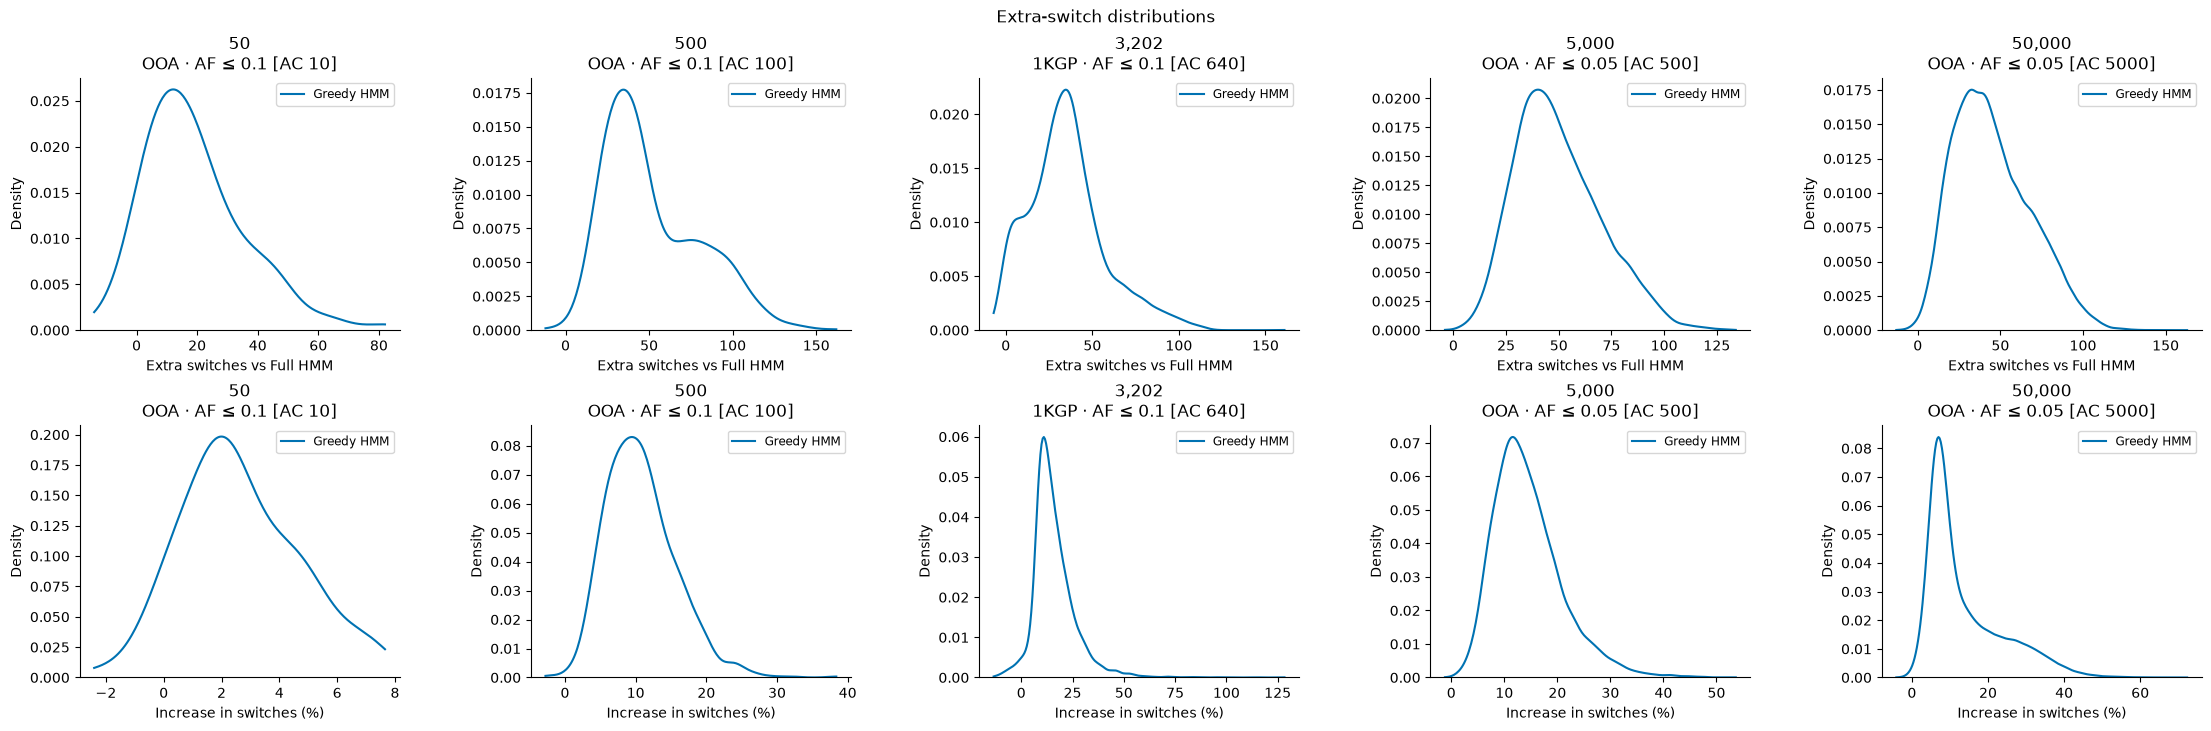

In [10]:
if __name__ == "__main__":
    metrics = {
        "num_extra_switches_mean": "Extra switches per haplotype",
        "switch_increase_percentage_mean": "Extra switches vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Extra switches vs sample size",
            sem=True,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "extra_switches_scaling",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_extra_switch_distributions(
            plot_data,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            kde_grid_size=256,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "extra_switch_distributions",
        export_dpi=180,
    )

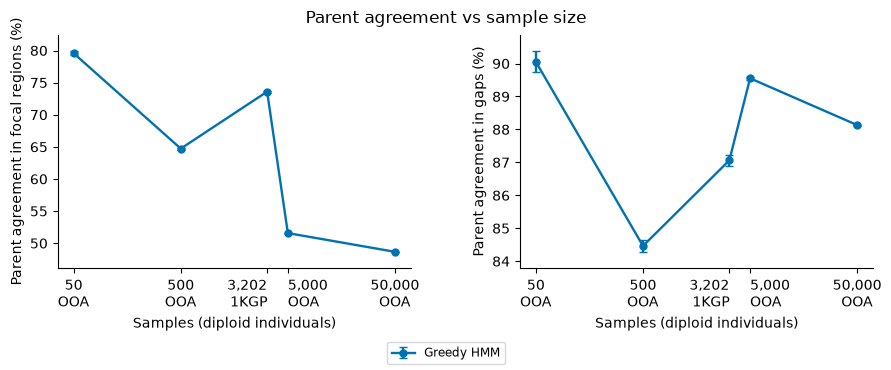

In [11]:
if __name__ == "__main__":
    metrics = {
        "focal_agreement_percentage_mean": "Parent agreement in focal regions (%)",
        "gap_agreement_percentage_mean": "Parent agreement in gaps (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            summary,
            metrics,
            "Parent agreement vs sample size",
            sem=True,
            zoom=True,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "parent_agreement_scaling",
        export_dpi=180,
    )

## Physical focal coverage and region lengths

Population groups follow the analysis config. Curves show physical coverage
over the archived analysis extent, with one haplotype SEM. Histograms show
**retained** connected focal regions at the cohort-specific minimum;
unfiltered regions were not archived. `num_bins` is directly editable below.
Dashed site thresholds are the actual filters. The physical-length markers
are mean-density equivalents, not strict physical cutoffs for each region.

Reflected Scott KDEs use every interval, including tails outside the displayed
pooled 99th percentile. Legends report the omitted tail fraction. Site and
physical lengths are cached as lossless frequency tables. Gap plots use
density curves and dashed median markers, with no histogram or coverage plot.

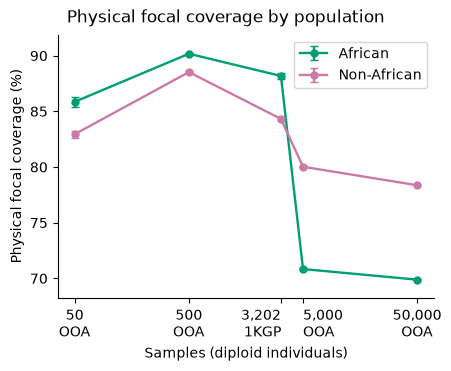

In [12]:
if __name__ == "__main__":
    population_coverage = nb_utils.population_coverage(config)
    lengths = nb_utils.perf_scaling_length_counts(config)
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_coverage(
            plot_data,
            population_coverage,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
            population_colors={"African": "#009E73", "Non-African": "#CC79A7"},
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "focal_population_coverage",
        export_dpi=180,
    )

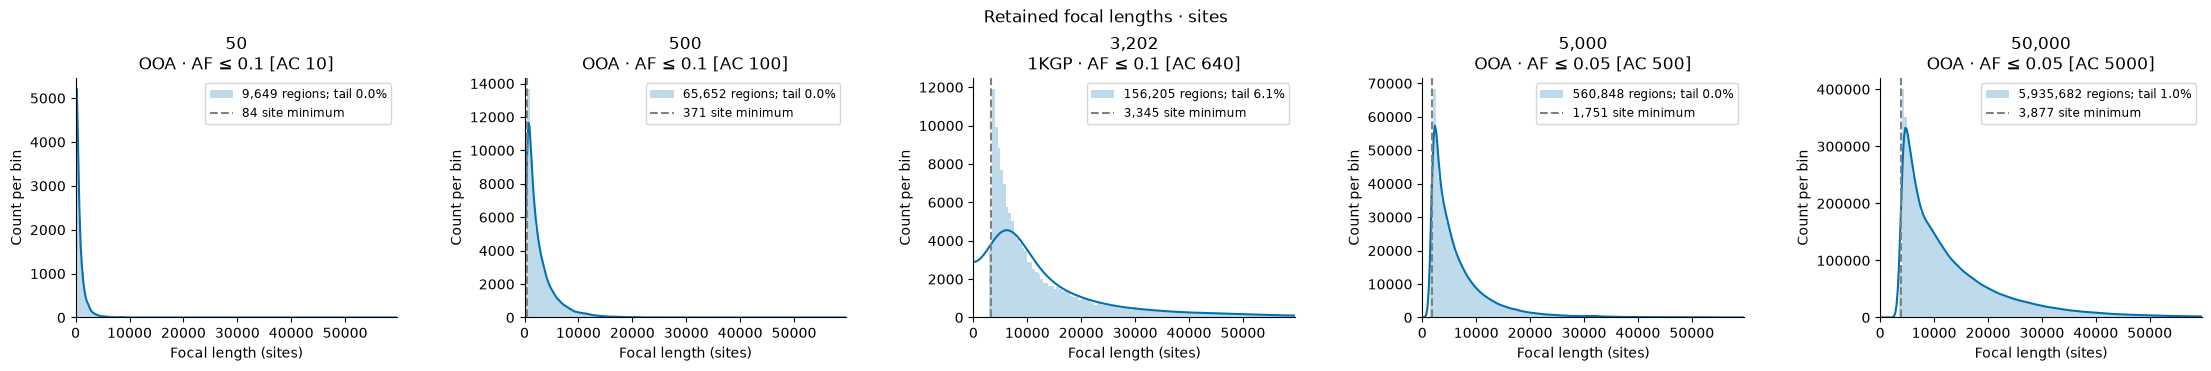

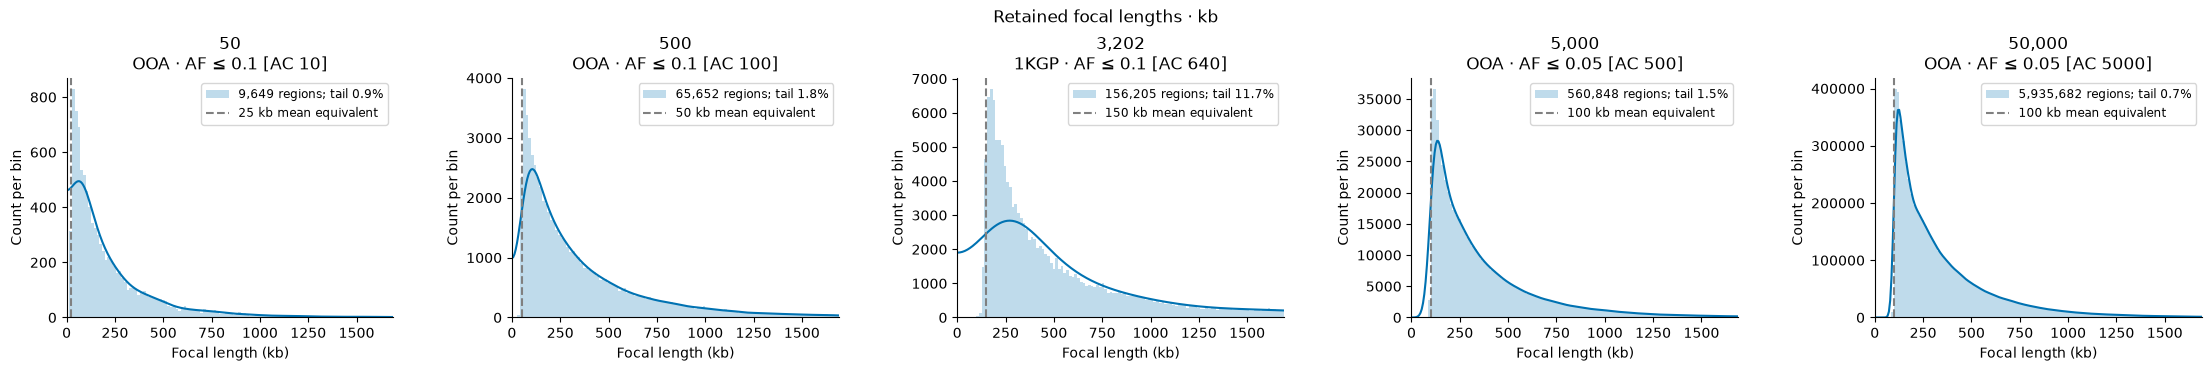

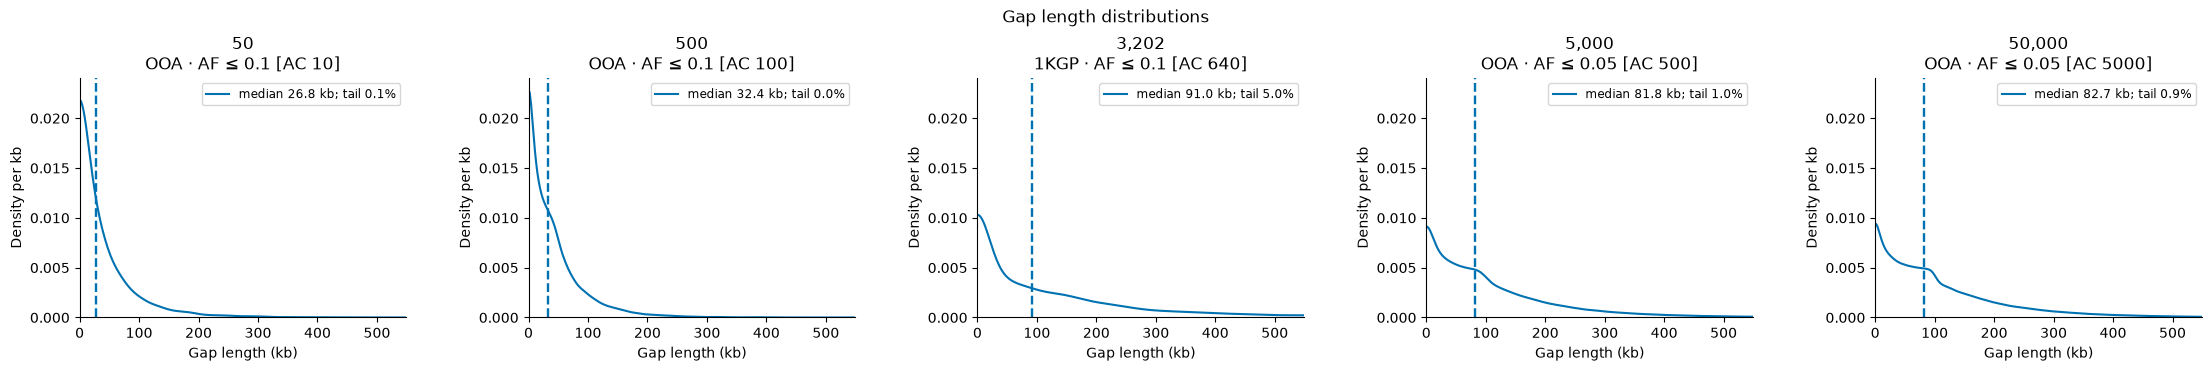

In [13]:
if __name__ == "__main__":
    num_bins = 120
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="sites",
            num_bins=num_bins,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "focal_lengths_sites",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_focal_lengths(
            plot_data,
            lengths,
            unit="kb",
            num_bins=num_bins,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            histogram_alpha=0.25,
            kde_grid_size=256,
            length_display_quantile=0.99,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "focal_lengths_kb",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_gap_lengths(
            plot_data,
            lengths,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            kde_grid_size=256,
            length_display_quantile=0.99,
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "gap_lengths_kb",
        export_dpi=180,
    )

### Recurrent sites

A recurrent site contains **two or more mutation records**, including back
mutations. Compare saved raw Full HMM and Greedy HMM trees before simplification
or dating, with truth restricted to the same archived inference-site positions.
Raw inferred trees retain reference ancestry, as in the tree-count plots below.
Counts use `np.bincount(ts.mutations_site)` rather than decoding genotypes.

The left panel counts recurrent sites; brackets above each bar give their
percentage of **all saved inference sites** in that cohort. The right panel
gives the mean number of mutation records **conditional on a site being
recurrent**, including the first event. Truth has no genotype errors; the
inferred trees were reconstructed from the error-containing calls.
An empty recurrent-site set has an undefined conditional mean and no bar.
Truth bars appear only for the four simulated datasets; 1KGP has none.

Recurrent sites: out_of_africa_n500_28_1mbp_error


Recurrent sites: out_of_africa_n5000_28_1mbp_error


Recurrent sites: out_of_africa_n50_28_1mbp_error


Recurrent sites: tgp_chr20p_n3202


Recurrent sites: out_of_africa_n50000_28_1mbp_error


,dataset,method,af_cutoff,num_sites,recurrent_sites,recurrent_site_percentage,mutations_at_recurrent_sites,mean_mutations_per_recurrent_site,additional_mutations,num_samples
6,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94665,0,0.000,0,NaN,0,50
7,out_of_africa_n50_28_1mbp_error,greedy,0.10,94665,3816,4.031,7979,2.091,4163,50
8,out_of_africa_n50_28_1mbp_error,truth,NaN,94665,337,0.356,675,2.003,338,50
0,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207968,0,0.000,0,NaN,0,500
1,out_of_africa_n500_28_1mbp_error,greedy,0.10,207968,24815,11.932,69044,2.782,44229,500
2,out_of_africa_n500_28_1mbp_error,truth,NaN,207968,1787,0.859,3578,2.002,1791,500
9,tgp_chr20p_n3202,full_hmm,NaN,580909,0,0.000,0,NaN,0,3202
10,tgp_chr20p_n3202,greedy,0.10,580909,14174,2.440,53508,3.775,39334,3202
3,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490670,0,0.000,0,NaN,0,5000
4,out_of_africa_n5000_28_1mbp_error,greedy,0.05,490670,58515,11.926,306715,5.242,248200,5000


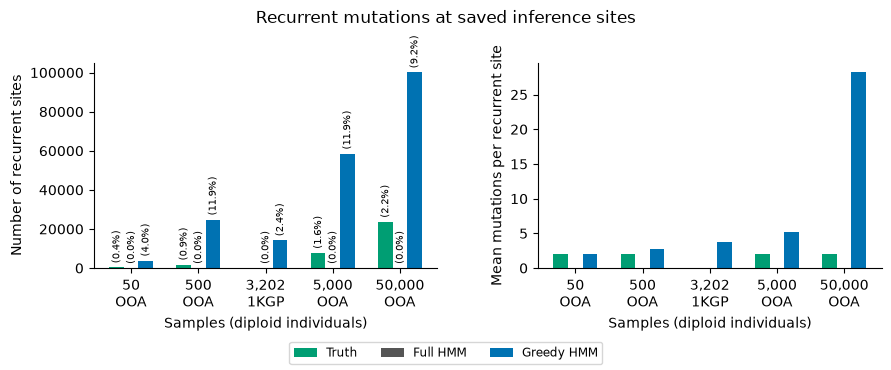

In [14]:
if __name__ == "__main__":
    recurrence = nb_utils.recurrent_sites(config)
    ipython_display.display(recurrence.round(3))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_recurrence(
            plot_data,
            recurrence,
            bar_width=0.65,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            stage_label_margin=0.22,
            truth_color="#009E73",
        ),
        "recurrent_sites",
        export_dpi=180,
    )

## Switch composition

Switches partition into within-focal, within-gap and seam categories. For
each cohort, Full HMM is partitioned with that same focal mask; its
total does not change with the mask. All columns display their y-axis ticks.

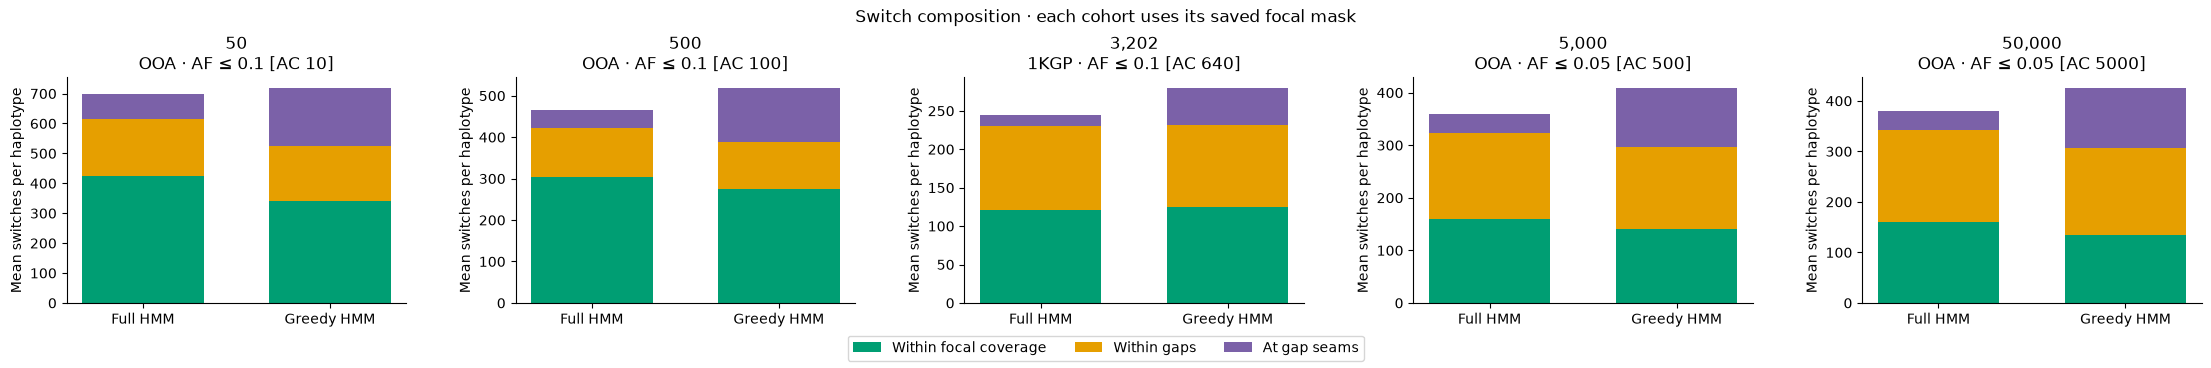

In [15]:
if __name__ == "__main__":
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_switch_composition(
            plot_data,
            summary,
            bar_width=0.65,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            switch_categories=["focal", "gap", "seam"],
            switch_colors=["#009E73", "#E69F00", "#7B61A8"],
            switch_labels=["Within focal coverage", "Within gaps", "At gap seams"],
        ),
        "switch_composition",
        export_dpi=180,
    )

## Direct ultimate-root to sample edges

These are raw copying edges from the ultimate ancestor (the child of the
vestigial root) directly to sample haplotypes, before root splitting or dating.
Count each edge once if it overlaps the common archived analysis extent;
its span is the number of observed base pairs, excluding chromosome flanks.
Counts and summed spans are divided by the cohort's haplotype count.

Each cohort uses its saved focal mask for **both** Full HMM and Greedy HMM paths.
An edge is **at a seam** if it overlaps a gap and contains an internal
focal/gap boundary, including either edge endpoint. An edge in a gap with
no such boundary is **gap interior**. Remaining edges are **focal only**.
Chromosome/domain ends are not seams. Edges spanning multiple regions are
counted once with seam classification taking precedence.

The difference panels subtract Full HMM from Greedy HMM within each category;
these are signed aggregate differences, not a pairing of individual edges.
Positive and negative contributions are stacked separately, with a diamond
marking the net difference. Moving an edge between categories can therefore
create opposite contributions even without changing the total edge count.

Histograms use common logarithmic bins over the **complete** observed span
range. Greedy HMM bars are stacked by location; Full HMM is the outline. Both
axes are logarithmic, and counts are edges per haplotype per bin.

Root/sample edges: out_of_africa_n50_28_1mbp_error


Root/sample edges: out_of_africa_n500_28_1mbp_error


Root/sample edges: tgp_chr20p_n3202


Root/sample edges: out_of_africa_n5000_28_1mbp_error


Root/sample edges: out_of_africa_n50000_28_1mbp_error


,num_samples,af_cutoff,method,category,edge_count,span_bp,edge_count_per_haplotype,span_kb_per_haplotype
0,50,0.10,full_hmm,seam,724,1968104.0,7.240,19.681
1,50,0.10,full_hmm,gap_interior,496,1796435.0,4.960,17.964
2,50,0.10,full_hmm,focal,622,1033301.0,6.220,10.333
3,50,0.10,greedy,seam,1784,2226903.0,17.840,22.269
4,50,0.10,greedy,gap_interior,491,1781959.0,4.910,17.820
5,50,0.10,greedy,focal,0,0.0,0.000,0.000
6,500,0.10,full_hmm,seam,3667,6831871.0,3.667,6.832
7,500,0.10,full_hmm,gap_interior,1688,3064507.0,1.688,3.065
8,500,0.10,full_hmm,focal,4057,7360007.0,4.057,7.360
9,500,0.10,greedy,seam,10799,6068569.0,10.799,6.069


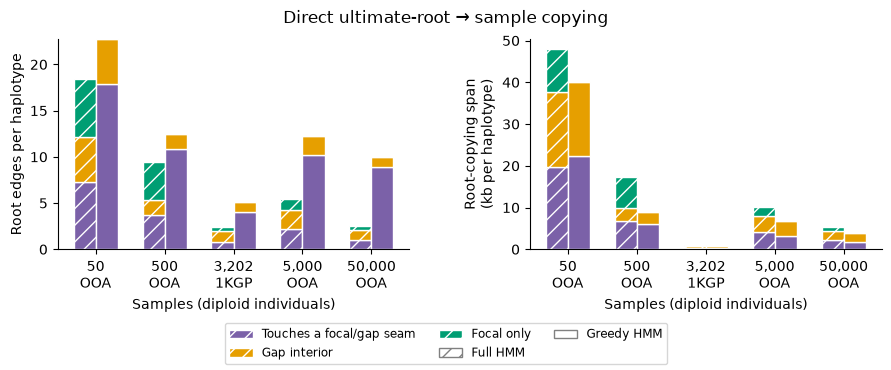

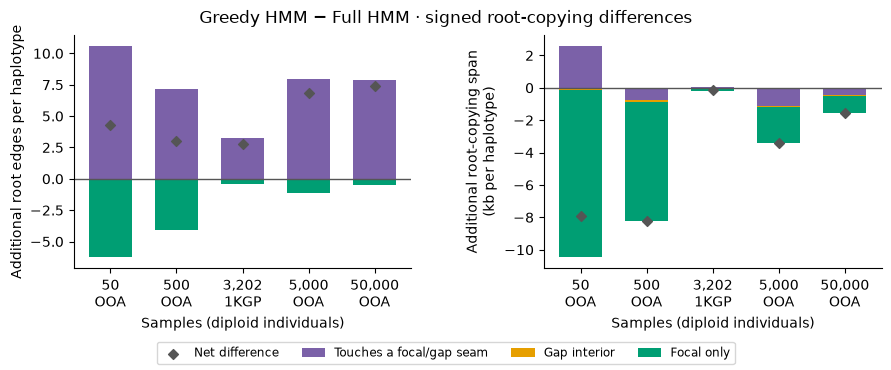

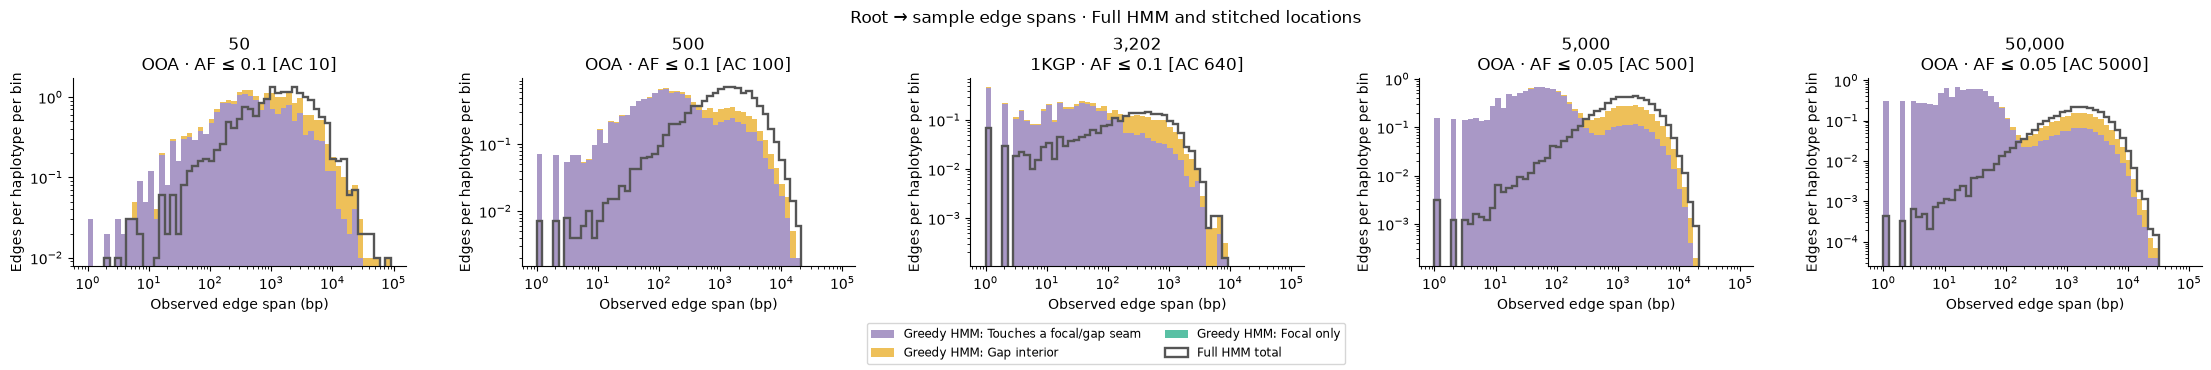

In [16]:
if __name__ == "__main__":
    root_edges = nb_utils.root_edge_summary(config)
    columns = [
        "num_samples",
        "af_cutoff",
        "method",
        "category",
        "edge_count",
        "span_bp",
        "edge_count_per_haplotype",
        "span_kb_per_haplotype",
    ]
    ipython_display.display(root_edges[columns].round(3))
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_totals(
            plot_data,
            root_edges,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            grouped_bar_width=0.32,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_counts_spans",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_differences(
            plot_data,
            root_edges,
            bar_width=0.65,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            full_color="#555555",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
        ),
        "root_edges_additional",
        export_dpi=180,
    )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_root_edge_spans(
            plot_data,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            full_color="#555555",
            line_width=1.7,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            root_edge_categories={
                "seam": {"label": "Touches a focal/gap seam", "color": "#7B61A8"},
                "gap_interior": {"label": "Gap interior", "color": "#E69F00"},
                "focal": {"label": "Focal only", "color": "#009E73"},
            },
            root_edge_histogram_alpha=0.65,
            root_edge_histogram_bins=55,
        ),
        "root_edges_span_histograms",
        export_dpi=180,
    )

## Saved tree counts and mutation dating

The following step checks that diagnostic and timed outputs have identical
copying paths and mutations, then records raw edge/tree counts. It computes
no ARF, TPR or other ARG metrics. Percentage changes use the raw Full HMM
counts, including retained reference ancestry.

Dating follows pt6/pt7: post-process saved trees, restrict to the common
archived extent, preprocess disjoint nodes and run variational-gamma tsdate.
**No variants are restored and no genotype stores are opened.** Mutation
rate is 2.35 × 10⁻⁸ per bp per generation, as in pt11; for 1KGP this is an
assumed rate rather than an estimate from these data. Independent trees run in worker
processes and their dated outputs are cached.

Dated out_of_africa_n5000_28_1mbp_error_full_hmm (1/10)


Dated out_of_africa_n50_28_1mbp_error_full_hmm (2/10)


Dated out_of_africa_n500_28_1mbp_error_af_0.1_kb_50 (3/10)


Dated out_of_africa_n500_28_1mbp_error_full_hmm (4/10)


Dated out_of_africa_n50_28_1mbp_error_af_0.1_kb_25 (5/10)


Dated out_of_africa_n5000_28_1mbp_error_af_0.05_kb_100 (6/10)


Dated tgp_chr20p_n3202_af_0.1_kb_150 (7/10)


Dated tgp_chr20p_n3202_full_hmm (8/10)


Dated out_of_africa_n50000_28_1mbp_error_full_hmm (9/10)


Dated out_of_africa_n50000_28_1mbp_error_af_0.05_kb_100 (10/10)


,dataset,method,af_cutoff,raw_sites,dated_sites,num_edges,num_trees,benchmark_paths_identical
0,out_of_africa_n50000_28_1mbp_error,full_hmm,NaN,1086350,1086349,64478936,1075757,True
1,out_of_africa_n50000_28_1mbp_error,greedy,0.05,1086350,1086349,68991442,1064513,True
2,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490670,490669,14515029,459378,True
3,out_of_africa_n5000_28_1mbp_error,greedy,0.05,490670,490669,15012382,451825,True
4,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207968,207967,2825935,177362,True
5,out_of_africa_n500_28_1mbp_error,greedy,0.10,207968,207967,2877663,177641,True
6,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94665,94664,524412,64678,True
7,out_of_africa_n50_28_1mbp_error,greedy,0.10,94665,94664,526330,65561,True
8,tgp_chr20p_n3202,full_hmm,NaN,580909,580908,5745032,414142,True
9,tgp_chr20p_n3202,greedy,0.10,580909,580908,5970436,416511,True


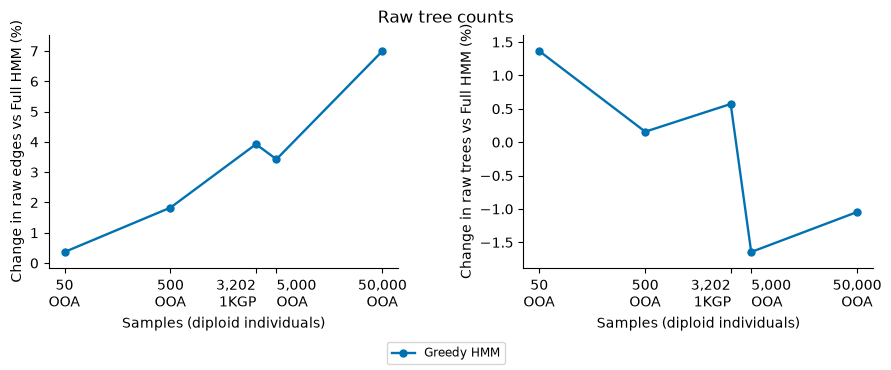

In [17]:
if __name__ == "__main__":
    dated = nb_utils.perf_scaling_date_all(config)
    ipython_display.display(
        dated[
            [
                "dataset",
                "method",
                "af_cutoff",
                "raw_sites",
                "dated_sites",
                "num_edges",
                "num_trees",
                "benchmark_paths_identical",
            ]
        ]
    )
    metrics = {
        "edges_change_percentage": "Change in raw edges vs Full HMM (%)",
        "trees_change_percentage": "Change in raw trees vs Full HMM (%)",
    }
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_scaling(
            plot_data,
            dated,
            metrics,
            "Raw tree counts",
            zoom=True,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            range_margin=0.08,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "raw_tree_counts",
        export_dpi=180,
    )

## Mutation ages: linear and rank correlation

Posterior **mutation means** (`mn`) are compared with simulated event times
and with Full HMM posterior means. Full HMM is a comparison method, not truth.

For simulations, use one common variant intersection across Full HMM, the
stitched run and truth. For 1KGP, intersect Full HMM and the stitched run only. Match position and ancestral/derived
states; exclude recurrent/back-mutation sites and nonfinite ages. All methods,
reference comparisons and frequency bins use that same cohort intersection.
The cached tables include its retention relative to each candidate set.

Pearson r uses untransformed ages in generations. Spearman rank correlation
compares age ordering using average ranks for tied ages. DAF is fixed from Full
HMM for every method; it is distinct from the AF cutoff used to select focal
ancestors. Bin boundaries enter the upper bin. Empty or constant-age bins
have undefined correlation and remain blank in the plots.

Mutation-age comparison complete: out_of_africa_n50_28_1mbp_error


Mutation-age comparison complete: out_of_africa_n500_28_1mbp_error


Mutation-age comparison complete: out_of_africa_n5000_28_1mbp_error


Mutation-age comparison complete: out_of_africa_n50000_28_1mbp_error


Mutation-age comparison complete: tgp_chr20p_n3202


frequency_bin,0.01 ≤ DAF < 0.5,DAF < 0.01,DAF ≥ 0.5,all
dataset,,,,
out_of_africa_n50000_28_1mbp_error,25249,939955,1856,967060
out_of_africa_n5000_28_1mbp_error,44611,377551,3662,425824
out_of_africa_n500_28_1mbp_error,71708,102973,7008,181689
out_of_africa_n50_28_1mbp_error,76330,0,14211,90541
tgp_chr20p_n3202,95371,425158,46205,566734


,dataset,method,af_cutoff,finite_single_mutation_sites,common_mutations,retained_percentage
0,out_of_africa_n50000_28_1mbp_error,full_hmm,NaN,1086349,967060,89.02
1,out_of_africa_n50000_28_1mbp_error,greedy,0.05,986289,967060,98.05
2,out_of_africa_n5000_28_1mbp_error,full_hmm,NaN,490669,425824,86.78
3,out_of_africa_n5000_28_1mbp_error,greedy,0.05,432154,425824,98.54
4,out_of_africa_n500_28_1mbp_error,full_hmm,NaN,207967,181689,87.36
5,out_of_africa_n500_28_1mbp_error,greedy,0.10,183152,181689,99.20
6,out_of_africa_n50_28_1mbp_error,full_hmm,NaN,94664,90541,95.64
7,out_of_africa_n50_28_1mbp_error,greedy,0.10,90848,90541,99.66
8,tgp_chr20p_n3202,full_hmm,NaN,580908,566734,97.56
9,tgp_chr20p_n3202,greedy,0.10,566734,566734,100.00


,dataset,num_samples,method,af_cutoff,reference_method,frequency_bin,matched_mutations,pearson_r,spearman_r,mean_error_generations,median_absolute_error_generations,mean_estimated_age,mean_reference_age
0,out_of_africa_n50_28_1mbp_error,50,full_hmm,NaN,truth,all,90541,0.7172,0.8509,-1083.4078,2140.7584,10064.5666,11147.9744
4,out_of_africa_n50_28_1mbp_error,50,greedy,0.10,truth,all,90541,0.7081,0.8509,-975.5696,2128.5587,10172.4048,11147.9744
8,out_of_africa_n50_28_1mbp_error,50,greedy,0.10,full_hmm,all,90541,0.9767,0.9910,107.8382,211.6538,10172.4048,10064.5666
12,out_of_africa_n500_28_1mbp_error,500,full_hmm,NaN,truth,all,181689,0.7503,0.8473,-281.6624,406.4138,3945.7693,4227.4317
16,out_of_africa_n500_28_1mbp_error,500,greedy,0.10,truth,all,181689,0.7138,0.8416,-218.5007,397.3434,4008.9310,4227.4317
20,out_of_africa_n500_28_1mbp_error,500,greedy,0.10,full_hmm,all,181689,0.9519,0.9814,63.1617,109.9374,4008.9310,3945.7693
24,out_of_africa_n5000_28_1mbp_error,5000,full_hmm,NaN,truth,all,425824,0.6998,0.7053,-207.4495,95.2278,1019.3365,1226.7860
28,out_of_africa_n5000_28_1mbp_error,5000,greedy,0.05,truth,all,425824,0.5664,0.6920,-182.2306,95.0130,1044.5554,1226.7860
32,out_of_africa_n5000_28_1mbp_error,5000,greedy,0.05,full_hmm,all,425824,0.8679,0.9617,25.2188,35.7395,1044.5554,1019.3365
36,out_of_africa_n50000_28_1mbp_error,50000,full_hmm,NaN,truth,all,967060,0.5174,0.3868,137.8586,42.0167,513.5063,375.6477


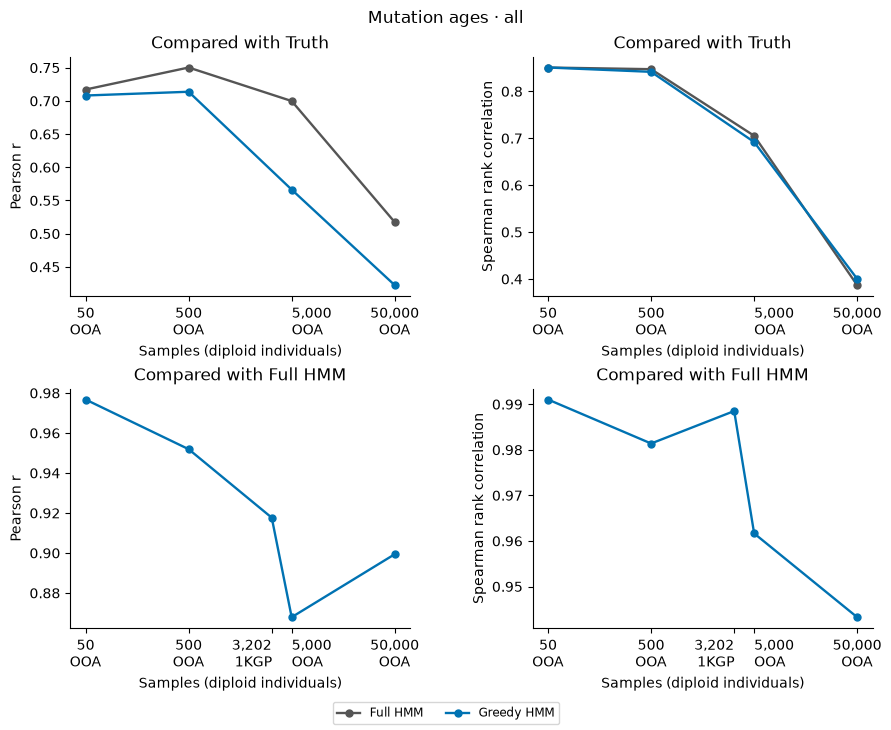

In [18]:
if __name__ == "__main__":
    ages = nb_utils.perf_scaling_mutation_correlations(config, dated)
    checks = ages.groupby(["dataset", "frequency_bin"]).matched_mutations.agg(
        ["min", "max"]
    )
    assert checks["min"].eq(checks["max"]).all()
    ipython_display.display(
        checks["min"].rename("matched_mutations").unstack("frequency_bin")
    )
    retention_paths = sorted(
        (config["cache_dir"] / "age_pairs").glob("*_retention.csv")
    )
    retention = pd.concat(
        [pd.read_csv(path) for path in retention_paths], ignore_index=True
    )
    ipython_display.display(retention.round(2))
    ipython_display.display(ages.loc[ages.frequency_bin.eq("all")].round(4))
    age_metrics = {"pearson_r": "Pearson r", "spearman_r": "Spearman rank correlation"}
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_correlations(
            plot_data,
            ages,
            metrics=age_metrics,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            cutoff_colors=["#0072B2", "#D55E00"],
            full_color="#555555",
            line_width=1.7,
            marker="o",
            marker_size=5,
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
            real_data_marker="o",
            sample_tick_alignments={
                "tgp_chr20p_n3202": "right",
                "out_of_africa_n5000_28_1mbp_error": "left",
            },
            sample_tick_rotation=0,
        ),
        "mutation_age_correlations",
        export_dpi=180,
    )

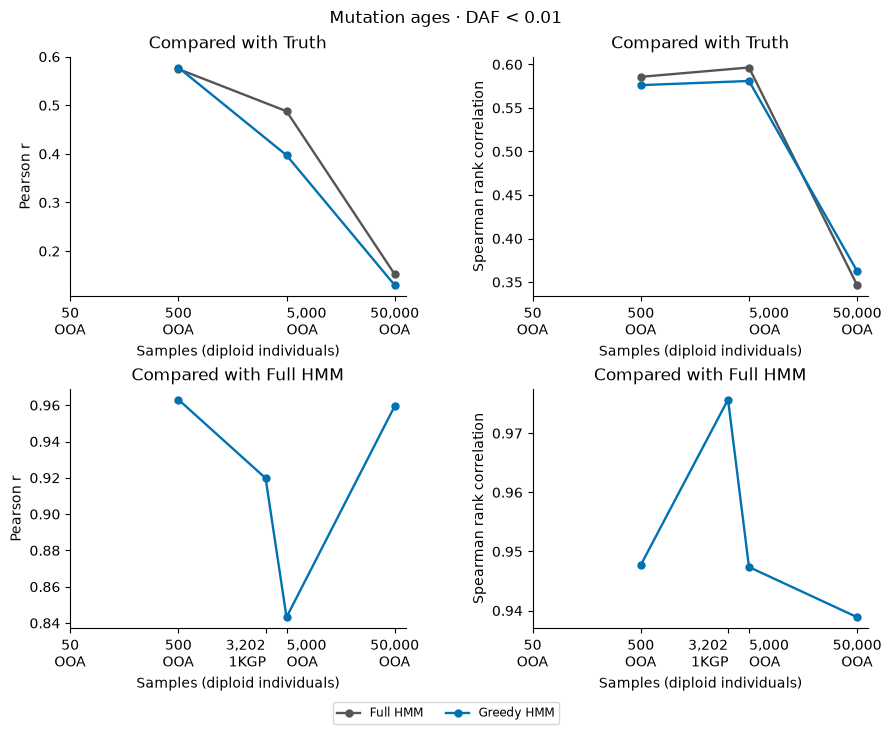

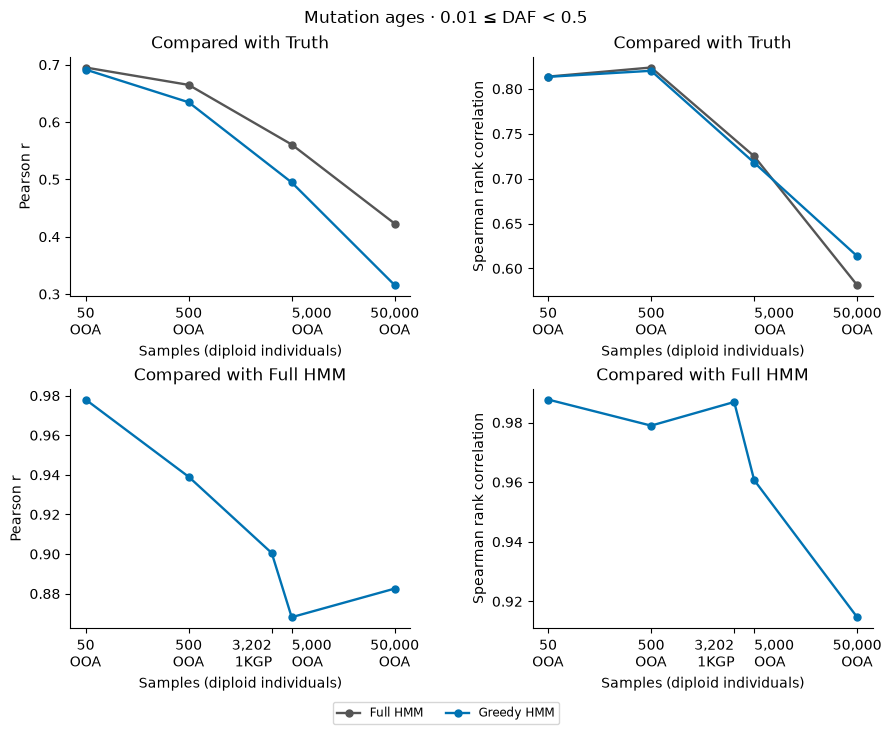

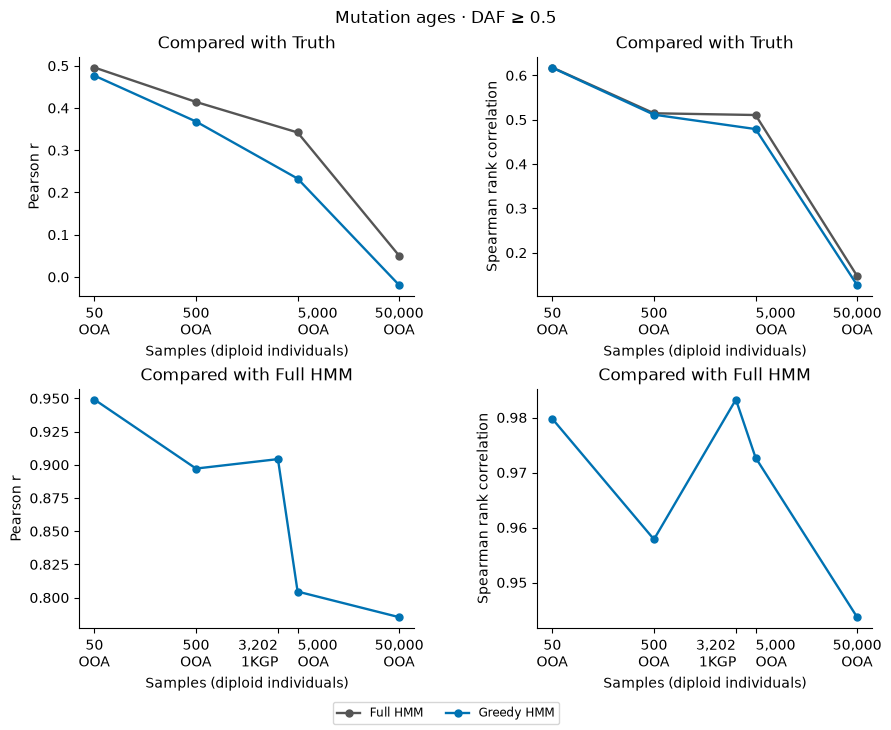

In [19]:
if __name__ == "__main__":
    for index, label in enumerate(config["frequency_bins"]["labels"]):
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_correlations(
                plot_data,
                ages,
                label,
                metrics=age_metrics,
                cohort_labels={
                    "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                    "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                    "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                    "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                    "tgp_chr20p_n3202": "3,202\n1KGP",
                },
                cutoff_colors=["#0072B2", "#D55E00"],
                full_color="#555555",
                line_width=1.7,
                marker="o",
                marker_size=5,
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=4.4,
                real_data_marker="o",
                sample_tick_alignments={
                    "tgp_chr20p_n3202": "right",
                    "out_of_africa_n5000_28_1mbp_error": "left",
                },
                sample_tick_rotation=0,
            ),
            f"mutation_age_daf_{index}",
            export_dpi=180,
        )

## Paired mutation ages

Hexagons show counts with one shared logarithmic colour scale. The dashed
line is equality. Display bounds omit ages below one generation and use a
shared upper quantile; correlations above use all matched ages,
including display tails. The annotated N is the complete common intersection.

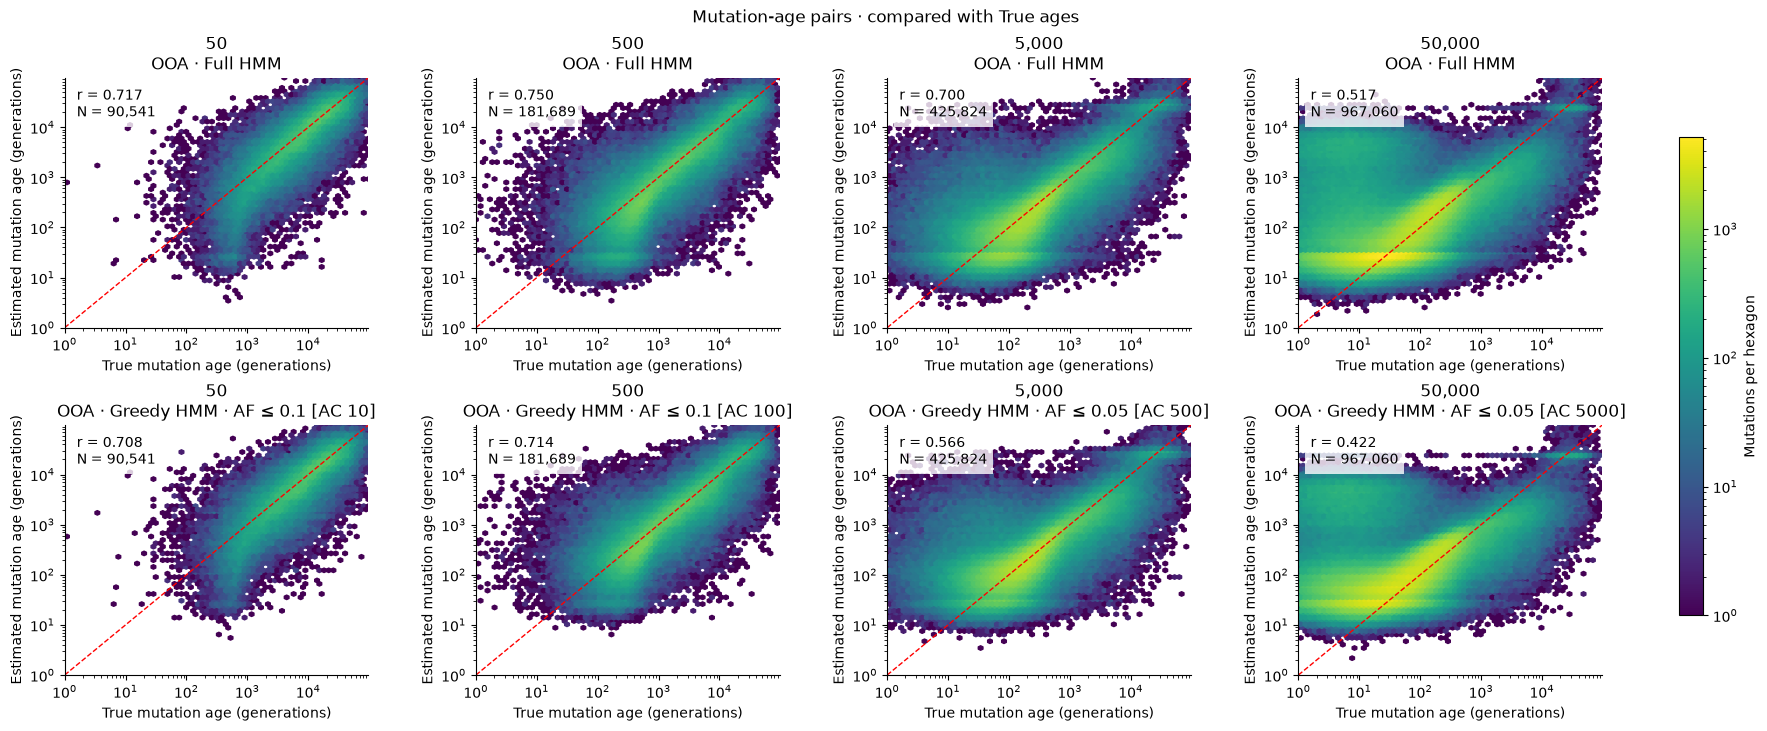

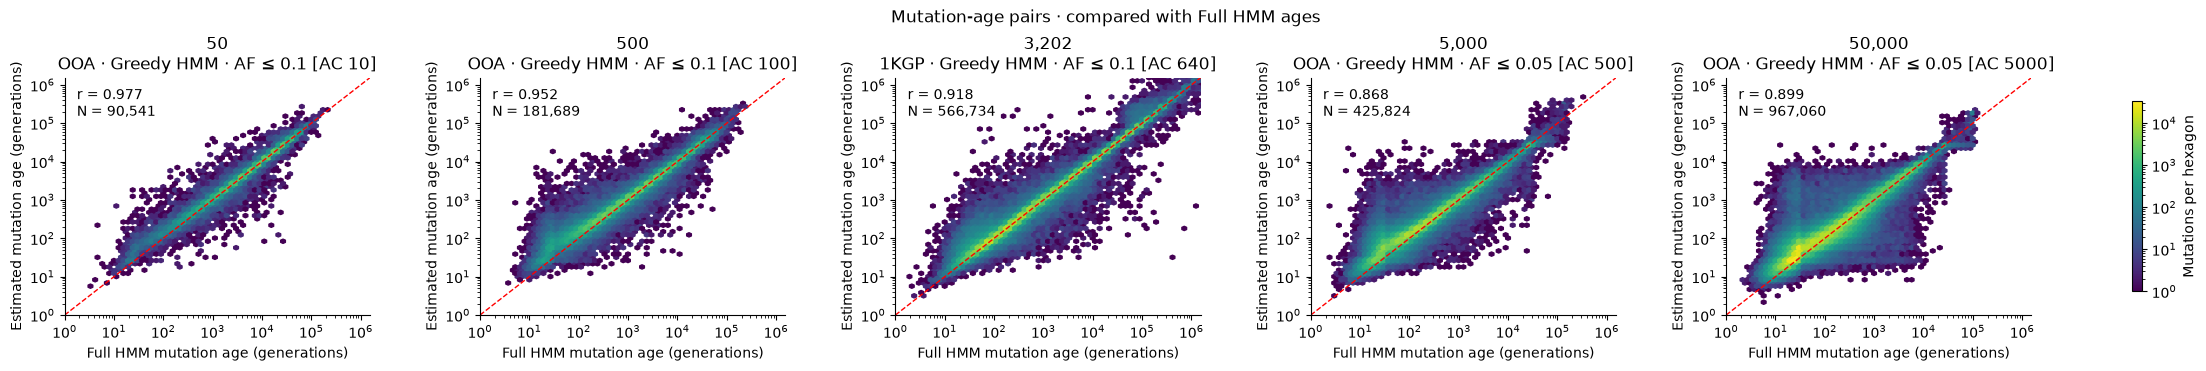

In [20]:
if __name__ == "__main__":
    if cohorts.has_truth.any():
        nb_plot.save_cohort_figure(
            plot_data,
            nb_plot.plot_age_density(
                plot_data,
                ages,
                "truth",
                age_hexbin_gridsize=65,
                age_maximum_quantile=0.999,
                age_minimum=1,
                cohort_labels={
                    "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                    "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                    "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                    "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                    "tgp_chr20p_n3202": "3,202\n1KGP",
                },
                method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
                method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
                panel_height=3.6,
                panel_width=4.4,
            ),
            "mutation_ages_vs_truth",
            export_dpi=180,
        )
    nb_plot.save_cohort_figure(
        plot_data,
        nb_plot.plot_age_density(
            plot_data,
            ages,
            "full_hmm",
            age_hexbin_gridsize=65,
            age_maximum_quantile=0.999,
            age_minimum=1,
            cohort_labels={
                "out_of_africa_n50_28_1mbp_error": "50\nOOA",
                "out_of_africa_n500_28_1mbp_error": "500\nOOA",
                "out_of_africa_n5000_28_1mbp_error": "5,000\nOOA",
                "out_of_africa_n50000_28_1mbp_error": "50,000\nOOA",
                "tgp_chr20p_n3202": "3,202\n1KGP",
            },
            method_colors={"full_hmm": "#555555", "greedy": "#0072B2"},
            method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
            panel_height=3.6,
            panel_width=4.4,
        ),
        "mutation_ages_vs_full_hmm",
        export_dpi=180,
    )

## Figures for the supervisor update (11 November 2026)

Run these cells after the perf5 analysis above has populated its caches.
Figure 1 uses **perf5** mutation-age correlations against simulated truth,
with Pearson and Spearman panels only. The example statistics use the
10,000-haplotype simulation. Figure 2 uses checked **perf5** performance
runs, excluding 50 diploids.
Its bars are discrete dataset categories; its two lines connect all four
datasets as visual guides, with one colour and point type per method. These
heterogeneous datasets do not form a controlled sample-size scaling experiment.
Average active cores are CPU time / wall time, not single-worker speedup.
PNG and PDF exports go to `figures/ch5/jerome_update_2026_11_11/`.

In [21]:
if __name__ == "__main__":
    report_dir = (repository_dir / "figures/ch5/jerome_update_2026_11_11").resolve()
    report_dir.mkdir(parents=True, exist_ok=True)
    report_config = {**config, "cache_dir": report_dir}
    report_data = nb_utils.prepare_scaling_data(report_config)
    report_ages = pd.read_csv(config["cache_dir"] / "mutation_age_correlations.csv")
    report_ages = report_ages.loc[
        report_ages.reference_method.eq("truth") & report_ages.frequency_bin.eq("all")
    ]
    report_summary = nb_utils.diagnostic_summary(config)
    example = report_summary.loc[
        report_summary.dataset.eq("out_of_africa_n5000_28_1mbp_error")
    ].iloc[0]
    example_ages = report_ages.loc[
        report_ages.dataset.eq("out_of_africa_n5000_28_1mbp_error")
    ]
    example_switch_increase = 100 * (
        example.stitched_switches_mean / example.full_switches_mean - 1
    )
    ipython_display.display(
        pd.Series(
            {
                "focal_coverage_percentage": example.focal_coverage_percentage_mean,
                "gap_site_parent_agreement_percentage": example.gap_agreement_percentage_mean,
                "switch_increase_ratio_of_means_percentage": example_switch_increase,
                "mean_per_haplotype_switch_increase_percentage": example.switch_increase_percentage_mean,
            }
        ).round(4)
    )
    ipython_display.display(
        example_ages[["method", "pearson_r", "spearman_r"]].round(4)
    )

focal_coverage_percentage                        76.9602
gap_site_parent_agreement_percentage             89.5518
switch_increase_ratio_of_means_percentage        13.8636
mean_per_haplotype_switch_increase_percentage    14.4845
dtype: float64

,method,pearson_r,spearman_r
24,full_hmm,0.6998,0.7053
28,greedy,0.5664,0.6920


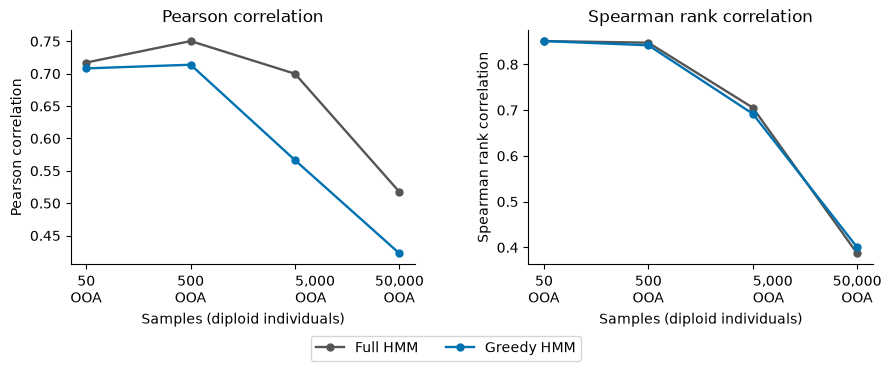

In [22]:
if __name__ == "__main__":
    figure, axes = nb_plot._cohort_panels(
        report_data,
        columns=len(
            {
                "pearson_r": "Pearson correlation",
                "spearman_r": "Spearman rank correlation",
            }
        ),
        panel_height=3.6,
        panel_width=4.4,
    )
    method_colors = {"full_hmm": "#555555", "greedy": "#0072B2"}
    nb_plot.plot_report_age_correlations(
        axes=axes,
        figure=figure,
        method_colors=method_colors,
        report_ages=report_ages,
        report_data=report_data,
        markersize=5,
        linewidth=1.7,
        age_metrics={
            "pearson_r": "Pearson correlation",
            "spearman_r": "Spearman rank correlation",
        },
        age_titles={
            "pearson_r": "Pearson correlation",
            "spearman_r": "Spearman rank correlation",
        },
        marker="o",
        method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
    )
    nb_plot.save_cohort_figure(
        report_data, figure, "figure_1_mutation_age_correlations", export_dpi=180
    )

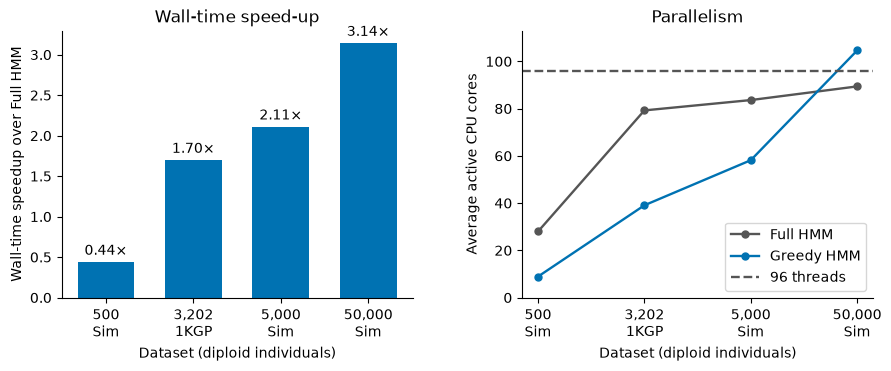

,num_samples,method,speedup,effective_cores,trial_peak_private_gib
2,500,full_hmm,1.000,27.981,4.725
3,500,greedy,0.436,8.902,15.058
9,3202,full_hmm,1.000,79.242,16.629
8,3202,greedy,1.696,39.077,22.245
5,5000,full_hmm,1.000,83.615,21.301
4,5000,greedy,2.108,58.163,22.790
6,50000,full_hmm,1.000,89.402,111.080
7,50000,greedy,3.140,104.625,66.193


In [23]:
if __name__ == "__main__":
    report_performance = nb_utils.performance_runs(config)
    included = ~report_performance.num_samples.isin([50])
    report_performance = report_performance.loc[included]
    stitched = report_performance.loc[
        report_performance.method.eq("greedy")
    ].sort_values("num_samples")
    figure, axes = nb_plot._cohort_panels(
        report_data, columns=2, panel_height=3.6, panel_width=4.4
    )
    speedup_ax, cores_ax = axes.flat
    positions = np.arange(len(stitched))
    dataset_labels = [
        {
            "out_of_africa_n500_28_1mbp_error": "500\nSim",
            "tgp_chr20p_n3202": "3,202\n1KGP",
            "out_of_africa_n5000_28_1mbp_error": "5,000\nSim",
            "out_of_africa_n50000_28_1mbp_error": "50,000\nSim",
        }[name]
        for name in stitched.dataset
    ]
    nb_plot.plot_report_speedup_parallelism(
        config=config,
        cores_ax=cores_ax,
        dataset_labels=dataset_labels,
        method_colors=method_colors,
        positions=positions,
        report_performance=report_performance,
        speedup_ax=speedup_ax,
        stitched=stitched,
        width=0.65,
        ylabel="Wall-time speedup over Full HMM",
        ylim=(0, None),
        markersize=5,
        linewidth=1.7,
        color="#555555",
        ylabel_2="Average active CPU cores",
        method_labels={"full_hmm": "Full HMM", "greedy": "Greedy HMM"},
        greedy_color="#0072B2",
        marker="o",
        worker_reference_linestyle="--",
        performance_xlabel="Dataset (diploid individuals)",
        parallelism_title="Parallelism",
        speedup_title="Wall-time speed-up",
        worker_reference_label="{workers} threads",
    )
    nb_plot.save_cohort_figure(
        report_data, figure, "figure_2_speedup_parallelism", export_dpi=180
    )
    ipython_display.display(
        report_performance[
            [
                "num_samples",
                "method",
                "speedup",
                "effective_cores",
                "trial_peak_private_gib",
            ]
        ].round(3)
    )